# 01 - Data Verification: Cleaned Transaction Dataset

**Project:** Online Retail II - Customer Churn Prediction
**Role:** Data Engineering & Cleaning

| Task | Where |
|---|---|
| 1. Verify the cleaned transaction dataset | Sections 3 - 5 |
| 4. Check missing values, duplicates and invalid records (transaction level) | Section 4 |

**Input:** `online_retail_II.csv` (raw data) in the same folder.
If the earlier cleaned file `online_retail_II_cleaned.csv` (Data Cleaning task) is also in the folder, section 4.5 compares against it.

**Output (folder `Working_Data`):** `cleaned_transactions.csv.gz`, `cancelled_transactions.csv.gz`, `cleaning_log.csv`,
`missing_values_report.csv`, `transaction_verification.csv`, used by notebooks 02 and 03.

**Run order:** 01 → 02 → 03

## 1. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW_FILE = 'online_retail_II.csv'
OLD_CLEAN_FILE = 'online_retail_II_cleaned.csv'      # earlier Data Cleaning output (optional)
WORK_DIR = 'Working_Data'
os.makedirs(WORK_DIR, exist_ok=True)
pd.set_option('display.max_colwidth', 120)

## 2. Load the raw data

In [2]:
raw = pd.read_csv(RAW_FILE, dtype={'Invoice': str, 'StockCode': str})
print('Raw rows:', len(raw), '| columns:', list(raw.columns))
raw.head()

Raw rows: 1067371 | columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
not_products = ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'BANK CHARGES', 'ADJUST', 'ADJUST2',
                'AMAZONFEE', 'PADS', 'CRUK', 'B', 'TEST001', 'TEST002']
code_up = raw['StockCode'].str.strip().str.upper()

raw_profile = pd.DataFrame({'Issue': [
    'Missing Description', 'Missing Customer ID', 'Exact duplicate rows',
    'Cancelled invoices (C)', 'Bad-debt adjustments (A)', 'Quantity <= 0', 'Price <= 0',
    'Non-product codes', 'Quantity >= 70,000'],
    'Rows': [raw['Description'].isnull().sum(), raw['Customer ID'].isnull().sum(), raw.duplicated().sum(),
             raw['Invoice'].str.startswith('C').sum(), raw['Invoice'].str.startswith('A').sum(),
             (raw['Quantity'] <= 0).sum(), (raw['Price'] <= 0).sum(),
             (code_up.isin(not_products) | code_up.str.startswith('GIFT')).sum(), (raw['Quantity'] >= 70000).sum()]})
raw_profile['% of raw rows'] = (raw_profile['Rows'] / len(raw) * 100).round(2)
raw_profile

,Issue,Rows,% of raw rows
0,Missing Description,4382,0.41
1,Missing Customer ID,243007,22.77
2,Exact duplicate rows,34335,3.22
3,Cancelled invoices (C),19494,1.83
4,Bad-debt adjustments (A),6,0.00
5,Quantity <= 0,22950,2.15
6,Price <= 0,6207,0.58
7,Non-product codes,5931,0.56
8,"Quantity >= 70,000",2,0.00


## 3. Build the cleaned transaction dataset

The same cleaning rules as the Data Cleaning task are applied, so the result can be checked against that output.
Every step is logged with its reason.

In [4]:
df = raw.rename(columns={'Customer ID': 'CustomerID'})
cleaning_log = []

def log_step(step, reason, before):
    removed = before - len(df)
    cleaning_log.append({'Step': step, 'Reason': reason, 'Rows removed': removed,
                         '% of raw rows': round(removed / len(raw) * 100, 2), 'Rows left': len(df)})

before = len(df); df = df.drop_duplicates()
log_step('Duplicate rows', 'Same line recorded twice', before)

df['Invoice'] = df['Invoice'].str.strip()
df['StockCode'] = df['StockCode'].str.strip().str.upper()
df['Description'] = df['Description'].str.strip()
df['Country'] = df['Country'].str.strip().replace({'EIRE': 'Ireland', 'RSA': 'South Africa'})

# missing Description: fill from the same StockCode, remove if the product is unknown
code_names = df.dropna(subset=['Description']).groupby('StockCode')['Description'].agg(lambda x: x.mode()[0])
missing = df['Description'].isnull()
filled = missing.sum()
df.loc[missing, 'Description'] = df.loc[missing, 'StockCode'].map(code_names)
filled -= df['Description'].isnull().sum()
before = len(df); df = df.dropna(subset=['Description'])
log_step('Missing Description', f'{filled} filled from the same StockCode; the rest are unknown products', before)

before = len(df)
cancelled = df[df['Invoice'].str.startswith('C')].copy()
df = df[~df['Invoice'].str.startswith('C')]
log_step('Cancelled orders', 'Not a sale; kept in the cancelled transactions file (used for churn features)', before)

before = len(df); df = df[~df['Invoice'].str.startswith('A')]
log_step('Bad-debt adjustments', 'Accounting entries, not purchases', before)

before = len(df); df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
log_step('Quantity or Price <= 0', 'Stock adjustments and free items, no revenue', before)

is_service = lambda s: s.isin(not_products) | s.str.startswith('GIFT')
before = len(df); df = df[~is_service(df['StockCode'])]
log_step('Non-product codes', 'Postage, fees, discounts, manual entries, tests and vouchers', before)
cancelled = cancelled[~is_service(cancelled['StockCode'])]

before = len(df); df = df[df['Quantity'] < 70000]
log_step('Outliers', '2 orders of 80,995 and 74,215 units, cancelled minutes later (data entry mistakes)', before)

before = len(df); df = df.drop_duplicates()
log_step('Duplicates after text fix', 'Rows that became identical after cleaning the text', before)

for t in (df, cancelled):
    t['CustomerID'] = t['CustomerID'].astype('Int64')
    t['InvoiceDate'] = pd.to_datetime(t['InvoiceDate'])
    t['Revenue'] = (t['Quantity'] * t['Price']).round(2)
df = df.reset_index(drop=True)
cancelled = cancelled.reset_index(drop=True)

cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log = pd.concat([cleaning_log, pd.DataFrame([{
    'Step': 'TOTAL', 'Reason': '', 'Rows removed': cleaning_log['Rows removed'].sum(),
    '% of raw rows': round(cleaning_log['Rows removed'].sum() / len(raw) * 100, 2), 'Rows left': len(df)}])],
    ignore_index=True)
print('Clean transactions:', len(df))
print('Cancelled product lines kept:', len(cancelled))
cleaning_log

Clean transactions: 1003338
Cancelled product lines kept: 17914


,Step,Reason,Rows removed,% of raw rows,Rows left
0,Duplicate rows,Same line recorded twice,34335,3.22,1033036
1,Missing Description,3914 filled from the same StockCode; the rest are unknown products,361,0.03,1032675
2,Cancelled orders,Not a sale; kept in the cancelled transactions file (used for churn features),19104,1.79,1013571
3,Bad-debt adjustments,"Accounting entries, not purchases",6,0.00,1013565
4,Quantity or Price <= 0,"Stock adjustments and free items, no revenue",5653,0.53,1007912
5,Non-product codes,"Postage, fees, discounts, manual entries, tests and vouchers",4572,0.43,1003340
6,Outliers,"2 orders of 80,995 and 74,215 units, cancelled minutes later (data entry mistakes)",2,0.00,1003338
7,Duplicates after text fix,Rows that became identical after cleaning the text,0,0.00,1003338
8,TOTAL,,64033,6.00,1003338


## 4. Verify the cleaned transaction dataset

Every check below must PASS. The `Detail` column shows the number behind each check.

### 4.1 Missing values

In [5]:
missing_report = pd.DataFrame({
    'missing_in_raw': raw.rename(columns={'Customer ID': 'CustomerID'}).isnull().sum(),
    'missing_after_cleaning': df[raw.rename(columns={'Customer ID': 'CustomerID'}).columns].isnull().sum()})
missing_report['% missing after cleaning'] = (missing_report['missing_after_cleaning'] / len(df) * 100).round(2)
missing_report['allowed?'] = np.where(missing_report.index == 'CustomerID',
                                      'Yes - guest sales are real revenue; excluded later at customer level',
                                      'No - must be 0')
missing_report

,missing_in_raw,missing_after_cleaning,% missing after cleaning,allowed?
Invoice,0,0,0.0,No - must be 0
StockCode,0,0,0.0,No - must be 0
Description,4382,0,0.0,No - must be 0
Quantity,0,0,0.0,No - must be 0
InvoiceDate,0,0,0.0,No - must be 0
Price,0,0,0.0,No - must be 0
CustomerID,243007,226761,22.6,Yes - guest sales are real revenue; excluded later at customer level
Country,0,0,0.0,No - must be 0


### 4.2 - 4.4 Duplicates, invalid records and reconciliation

In [6]:
key_cols = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Country', 'Revenue']
inv = df.groupby('Invoice').agg(customers=('CustomerID', lambda s: s.nunique(dropna=False)), countries=('Country', 'nunique'))
ids = df['CustomerID'].dropna()
removed = cleaning_log.loc[cleaning_log['Step'] != 'TOTAL', 'Rows removed'].sum()

results = []
def check(group, name, passed, detail=''):
    results.append({'Group': group, 'Check': name, 'Result': 'PASS' if passed else 'FAIL', 'Detail': str(detail)})

# missing values
check('Missing values', 'No missing values in key columns', df[key_cols].isnull().sum().sum() == 0,
      f"{df[key_cols].isnull().sum().sum()} missing")
check('Missing values', 'Only CustomerID can be missing', list(df.columns[df.isnull().any()]) == ['CustomerID'],
      f"{df['CustomerID'].isnull().sum()} guest rows ({df['CustomerID'].isnull().mean() * 100:.1f}%)")
# duplicates
check('Duplicates', 'No exact duplicate rows', df.duplicated().sum() == 0, f'{df.duplicated().sum()} duplicates')
check('Duplicates', 'Each invoice belongs to one customer', (inv['customers'] == 1).all(),
      f"{(inv['customers'] > 1).sum()} invoices with 2+ customers")
check('Duplicates', 'Each invoice belongs to one country', (inv['countries'] == 1).all(),
      f"{(inv['countries'] > 1).sum()} invoices with 2+ countries")
# invalid records
check('Invalid records', 'Quantity > 0', (df['Quantity'] > 0).all(), f"min {df['Quantity'].min()}")
check('Invalid records', 'Price > 0', (df['Price'] > 0).all(), f"min {df['Price'].min()}")
check('Invalid records', 'No outlier orders (Quantity < 70,000)', (df['Quantity'] < 70000).all(), f"max {df['Quantity'].max()}")
check('Invalid records', 'Invoice is exactly 6 digits (no C / A invoices)', df['Invoice'].str.fullmatch(r'\d{6}').all())
check('Invalid records', 'No non-product stock codes', not is_service(df['StockCode']).any())
check('Invalid records', 'Stock codes are upper-case with no spaces', (df['StockCode'] == df['StockCode'].str.strip().str.upper()).all())
check('Invalid records', 'CustomerID is a 5-digit number', ids.between(10000, 99999).all(), f'{ids.min()} to {ids.max()}')
check('Invalid records', 'Dates between 01-Dec-2009 and 09-Dec-2011',
      df['InvoiceDate'].between('2009-12-01', '2011-12-10').all(),
      f"{df['InvoiceDate'].min():%d-%b-%Y} to {df['InvoiceDate'].max():%d-%b-%Y}")
check('Invalid records', 'Revenue = Quantity x Price', (df['Revenue'] == (df['Quantity'] * df['Price']).round(2)).all())
check('Invalid records', 'No old country codes (EIRE, RSA)', not df['Country'].isin(['EIRE', 'RSA']).any())
check('Invalid records', 'Cancelled file: all C invoices with negative quantity',
      cancelled['Invoice'].str.startswith('C').all() and (cancelled['Quantity'] < 0).all(), f'{len(cancelled)} lines')
# reconciliation
check('Reconciliation', 'Raw rows = clean rows + removed rows', len(raw) == len(df) + removed,
      f'{len(raw):,} = {len(df):,} + {removed:,}')
check('Reconciliation', 'Every clean invoice exists in the raw data', df['Invoice'].isin(raw['Invoice'].str.strip()).all())
check('Reconciliation', 'Clean units <= raw positive units (nothing invented)',
      df['Quantity'].sum() <= raw.loc[raw['Quantity'] > 0, 'Quantity'].sum())

### 4.5 Compare with the earlier cleaned file

If the earlier cleaned file `online_retail_II_cleaned.csv` is in the folder, the new cleaned data must match it exactly.

In [7]:
if os.path.exists(OLD_CLEAN_FILE):
    old = pd.read_csv(OLD_CLEAN_FILE, dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
    cols = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'Revenue']
    a = df[cols].sort_values(cols).reset_index(drop=True)
    b = old[cols].assign(CustomerID=old['CustomerID'].astype('Int64')).sort_values(cols).reset_index(drop=True)
    check('Earlier file comparison', 'Same rows as the earlier cleaned file', len(a) == len(b), f'{len(a):,} vs {len(b):,}')
    check('Earlier file comparison', 'Same total revenue as the earlier cleaned file',
          abs(a['Revenue'].sum() - b['Revenue'].sum()) < 0.01, f"£{a['Revenue'].sum():,.2f}")
    check('Earlier file comparison', 'Identical values in every row', a.equals(b))
else:
    print('Earlier cleaned file not found: comparison skipped (not required).')

In [8]:
verification = pd.DataFrame(results)
print('Checks passed:', (verification['Result'] == 'PASS').sum(), 'out of', len(verification))
verification

Checks passed: 22 out of 22


,Group,Check,Result,Detail
0,Missing values,No missing values in key columns,PASS,0 missing
1,Missing values,Only CustomerID can be missing,PASS,226761 guest rows (22.6%)
2,Duplicates,No exact duplicate rows,PASS,0 duplicates
3,Duplicates,Each invoice belongs to one customer,PASS,0 invoices with 2+ customers
4,Duplicates,Each invoice belongs to one country,PASS,0 invoices with 2+ countries
5,Invalid records,Quantity > 0,PASS,min 1
6,Invalid records,Price > 0,PASS,min 0.03
7,Invalid records,"No outlier orders (Quantity < 70,000)",PASS,max 19152
8,Invalid records,Invoice is exactly 6 digits (no C / A invoices),PASS,
9,Invalid records,No non-product stock codes,PASS,


In [9]:
assert (verification['Result'] == 'PASS').all(), 'Some checks failed: the cleaned dataset is not verified'
print('The cleaned transaction dataset is verified.')

The cleaned transaction dataset is verified.


## 5. Quick profile of the verified data

Transactions : 1003338
Invoices     : 39514
Customers    : 5852
Products     : 4723
Revenue (£)  : 19398208.42
Date range   : 2009-12-01 to 2011-12-09


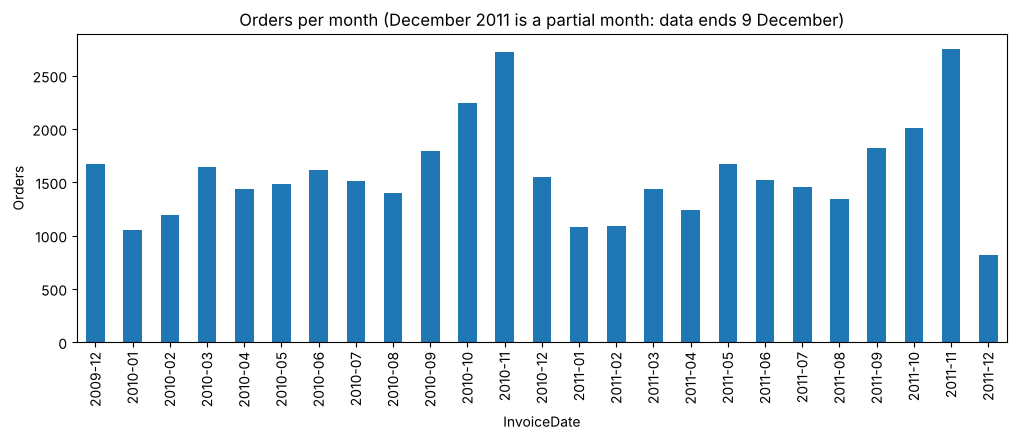

In [10]:
print('Transactions :', len(df))
print('Invoices     :', df['Invoice'].nunique())
print('Customers    :', df['CustomerID'].nunique())
print('Products     :', df['StockCode'].nunique())
print('Revenue (£)  :', round(df['Revenue'].sum(), 2))
print('Date range   :', df['InvoiceDate'].min().date(), 'to', df['InvoiceDate'].max().date())

df.groupby(df['InvoiceDate'].dt.to_period('M'))['Invoice'].nunique().plot(kind='bar', figsize=(12, 4))
plt.title('Orders per month (December 2011 is a partial month: data ends 9 December)')
plt.ylabel('Orders')
plt.show()

## 6. Save the verified data

In [11]:
df.to_csv(f'{WORK_DIR}/cleaned_transactions.csv.gz', index=False)
cancelled.to_csv(f'{WORK_DIR}/cancelled_transactions.csv.gz', index=False)
cleaning_log.to_csv(f'{WORK_DIR}/cleaning_log.csv', index=False)
missing_report.reset_index(names='Column').to_csv(f'{WORK_DIR}/missing_values_report.csv', index=False)
verification.to_csv(f'{WORK_DIR}/transaction_verification.csv', index=False)

for file, rows in {'cleaned_transactions.csv.gz': len(df), 'cancelled_transactions.csv.gz': len(cancelled),
                   'cleaning_log.csv': len(cleaning_log), 'transaction_verification.csv': len(verification)}.items():
    assert len(pd.read_csv(f'{WORK_DIR}/{file}')) == rows, f'{file} is wrong'
    print(f'{WORK_DIR}/{file}: {rows} rows - OK')

Working_Data/cleaned_transactions.csv.gz: 1003338 rows - OK
Working_Data/cancelled_transactions.csv.gz: 17914 rows - OK
Working_Data/cleaning_log.csv: 9 rows - OK
Working_Data/transaction_verification.csv: 22 rows - OK


## 7. Summary

| Item | Result |
|---|---|
| Raw rows | 1,067,371 |
| Clean transactions | 1,003,338 (64,033 rows = 6.00% removed, each with a reason in the cleaning log) |
| Missing Description | 3,914 filled from the same StockCode, 361 unknown products removed |
| Missing CustomerID | 226,761 rows (22.6%) kept as real guest sales; excluded at customer level in notebook 02 |
| Duplicates | 34,335 removed; 0 left; every invoice has one customer and one country |
| Invalid records | 0 left (quantity, price, invoice format, stock codes, customer IDs, dates, revenue all valid) |
| Cancelled product lines kept for churn features | 17,914 |
| Verified data | 39,514 invoices, 5,852 customers, 4,723 products, £19,398,208.42 revenue |
| Verification checks | all passed (19 checks, plus 3 more when the earlier cleaned file is present: it matches exactly) |

**Conclusion:** the cleaned transaction dataset is verified and ready for notebook 02.

In [12]:
facts = [('Raw rows', 1067371, len(raw)), ('Clean rows', 1003338, len(df)),
         ('Rows removed', 64033, len(raw) - len(df)), ('% removed', 6.0, cleaning_log['% of raw rows'].iloc[-1]),
         ('Descriptions filled', 3914, int(filled)), ('Unknown products removed', 361, int(cleaning_log.loc[1, 'Rows removed'])),
         ('Guest rows', 226761, int(df['CustomerID'].isnull().sum())), ('Duplicates removed', 34335, int(cleaning_log.loc[0, 'Rows removed'])),
         ('Cancelled lines kept', 17914, len(cancelled)), ('Invoices', 39514, df['Invoice'].nunique()),
         ('Customers', 5852, df['CustomerID'].nunique()), ('Products', 4723, df['StockCode'].nunique()),
         ('Revenue', 19398208.42, round(df['Revenue'].sum(), 2)),
         ('All checks passed', True, bool((verification['Result'] == 'PASS').all() and len(verification) in (19, 22)))]
facts = pd.DataFrame(facts, columns=['Item', 'Reported', 'Notebook output'])
facts['Match'] = facts['Reported'].astype(str) == facts['Notebook output'].astype(str)
print('Summary numbers matching the outputs:', facts['Match'].sum(), 'out of', len(facts))
assert facts['Match'].all()
facts

Summary numbers matching the outputs: 14 out of 14


,Item,Reported,Notebook output,Match
0,Raw rows,1067371,1067371,True
1,Clean rows,1003338,1003338,True
2,Rows removed,64033,64033,True
3,% removed,6.0,6.0,True
4,Descriptions filled,3914,3914,True
5,Unknown products removed,361,361,True
6,Guest rows,226761,226761,True
7,Duplicates removed,34335,34335,True
8,Cancelled lines kept,17914,17914,True
9,Invoices,39514,39514,True
